# A Time-Based Evaluation of K-Nearest Neighbors for Major League Baseball Pitch Classification

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

Major League Baseball broadcasts display pitch types in real time, shortly after a pitch is thrown. THis requires a model that can predict pitch type nearly instantaneously from tracking measurements captured immediately at release. In this report. I devgelop a proof-of-concept pitch classification model for Kevin Gausman using statcast features available in real time - release speed, spin rate, and pitch movement, along with batter handedness. I evaluate performance on a time-based split. 2024 season for training, first half of 2025 for testing to approximate real deployment conditions where pitcher behavior can shift over time. 

## Methods

In [3]:
# imports
import pandas as pd
import numpy as np
from joblib import dump
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

### Data

In [4]:
# load data
pitches_train = pd.read_csv(
    "pitches-train.csv",
)
pitches_test = pd.read_csv(
    "pitches-test.csv",
)

The dataset contains statcast measurements for individual pitches thrown by Kevin Gausman during MLB regular season games. The training set contains pitches from the 2024 season and the test set contains pitches from the first half of the 2025 season, creating a time-based split that better reflects deployment than a random split. 


| Variable | Type | Description |
|----------|------|-------------|
| pitch_type | object | The type of pitch thrown (target variable) |
| release_speed | float | Pitch velocity in miles per hour measured shortly after release |
| release_spin_rate | float | Spin rate in revolutions per minute measured shortly after release |
| pfx_x | float | Horizontal movement (feet) from the catcher’s perspective |
| pfx_z | float | Vertical movement (feet) from the catcher’s perspective |
| stand | object | Batter stance: L (left) or R (right) |

Samples and features:

In [5]:
# summary statistics
pitches_train.shape

(2868, 6)

Count for Each Pitch Type:

In [6]:
pitches_train["pitch_type"].value_counts()

pitch_type
FF    1488
FS     959
SL     240
SI     181
Name: count, dtype: int64

Proportion of Each Pitch Type:

In [7]:
pitches_train["pitch_type"].value_counts() / len(pitches_train)

pitch_type
FF    0.518828
FS    0.334379
SL    0.083682
SI    0.063110
Name: count, dtype: float64

Mean Velocity for Each Pitch Type:

In [8]:
pitches_train.groupby("pitch_type")["release_speed"].mean()

pitch_type
FF    93.957527
FS    85.969552
SI    93.310497
SL    82.747917
Name: release_speed, dtype: float64

Standard Deviation of the Velocity for Each Pitch Type:

In [9]:
pitches_train.groupby("pitch_type")["release_speed"].std()

pitch_type
FF    1.700911
FS    1.821758
SI    1.739876
SL    1.864128
Name: release_speed, dtype: float64

Mean Spin Rate for Each Pitch Type:

In [10]:
pitches_train.groupby("pitch_type")["release_spin_rate"].mean()

pitch_type
FF    2287.098118
FS    1764.038582
SI    2189.022099
SL    2239.435146
Name: release_spin_rate, dtype: float64

Standard Deviation of The Spin Rate for Each Pitch Type:

In [11]:
pitches_train.groupby("pitch_type")["release_spin_rate"].std()

pitch_type
FF    101.983970
FS    177.469770
SI    113.026494
SL     96.452687
Name: release_spin_rate, dtype: float64

My summary statsitics shows the dataset contains 2868 samples and 5 features. I computed the count and proportion of each pitch type. I calculated the mean and standard deviation of release velocity and spin rate for each pitch type to summarize their basic characteristics.

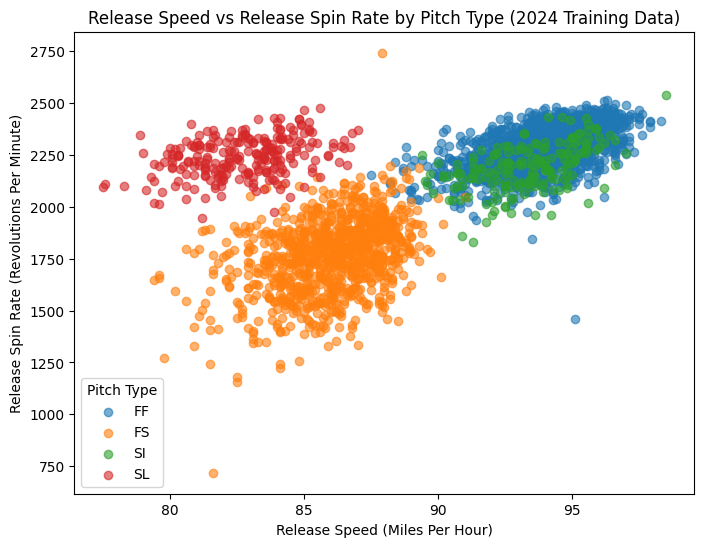

In [12]:
#| fig-cap: "Release Speed and Spin Rate by Pitch Type in the 2024 Training Data"
# exploratory visualization
plt.figure(figsize=(8, 6))

pitch_colors = {
    "FF": "tab:blue",
    "FS": "tab:orange",
    "SI": "tab:green",
    "SL": "tab:red"
}

for pitch, color in pitch_colors.items():
    subset = pitches_train[pitches_train["pitch_type"] == pitch]
    plt.scatter(
        subset["release_speed"],
        subset["release_spin_rate"],
        label=pitch,
        color=color,
        alpha=0.6
    )

plt.xlabel("Release Speed (Miles Per Hour)")
plt.ylabel("Release Spin Rate (Revolutions Per Minute)")
plt.title("Release Speed vs Release Spin Rate by Pitch Type (2024 Training Data)")
plt.legend(title="Pitch Type")
plt.show()


### Models

In [13]:
# process data for ML
X_train = pitches_train.drop("pitch_type", axis=1)
y_train = pitches_train["pitch_type"]
X_test = pitches_test.drop("pitch_type", axis=1)
y_test = pitches_test["pitch_type"]

In [14]:
# train models
numeric_features = list(X_train.select_dtypes(include=["number"]).columns)
categorical_features = list(X_train.columns.difference(numeric_features))

# define preprocessing for numeric features
numeric_transformer = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# define preprocessing for categorical features
categorical_transformer = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# define a transformation of the columns
column_transformer = ColumnTransformer(
    [
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

# create the KNN pipeline
knn = Pipeline(
    [
        ("preprocessor", column_transformer),
        ("classifier", KNeighborsClassifier(n_neighbors=10,weights="distance",p=2)),
    ]
)

# fit and evaluate
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)


The pitch type prediction task was treated as a multi-class classification problem using release speed, spin rate, horizontal movement, vertical movement, and batter stance as predictors. Numeric features were imputed using the median and standardized, while the categorical feature (stand) was imputed using the most frequent value and encoded using one-hot encoding. These preprocessing steps were combined using a column transformer and included within a single sklearn pipeline to ensure consistent processing during both training and prediction. A K-Nearest Neighbors (KNN) classifier with 10 neighbors and distance-based weighting was trained on the 2024 season data and evaluated on the 2025 test data to reflect a realistic deployment scenario.

## Results

In [15]:
# report model metrics
test_acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9834

Classification Report:
              precision    recall  f1-score   support

          FF       1.00      0.98      0.99       967
          FS       0.99      0.99      0.99       693
          SI       0.05      0.50      0.08         2
          SL       0.99      0.96      0.98       144

    accuracy                           0.98      1806
   macro avg       0.76      0.86      0.76      1806
weighted avg       0.99      0.98      0.99      1806



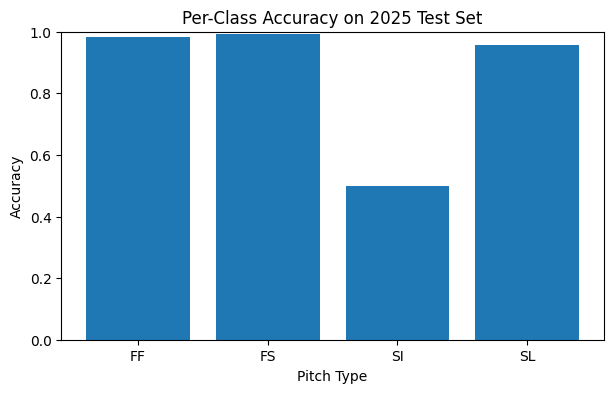

In [16]:
#| fig-cap: "Per-Class Accuracy of the Selected K-Nearest Neighbors Model on the 2025 Test Data"
# summary figure
labels = knn.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(7, 4))
plt.bar(labels, per_class_accuracy)
plt.xlabel("Pitch Type")
plt.ylabel("Accuracy")
plt.title("Per-Class Accuracy on 2025 Test Set")
plt.ylim(0, 1)
plt.show()

The selected K-Nearest Neighbors model was evaluated on the 2025 test dataset using a time-based split. The model achieved high overall accuracy on the test set, indicating stron gpredictive performance on unseen data. Precision and recall were also high for the most frequently occurring pitch types, demonstrating that the model reliably identifies dominant categories.

However, performance varied across classes. WHile common pitch types were classified with stron gprecision and recall, rare pitch types showed a weaker performance, reflecting class imbalance in the dataset. As a result, weighted evaluation metrics were higher than macro-averaged metrics, indicating that overall performance was driven primarily by the majority classes. 

Overall, the results suggest that the model generalizes well to new seasonal data, with strong predictive performance for the primary pitch types. 

## Discussion

Based on the results presented above, I would recommend deploying this model for real-time pitch classification. The model demonstrated strong predictive performance on unseen 2025 data, suggesting that it generalizes well beyond the training season. Because a time-based split was used, the evaluation more closely reflects how the model would perform in a real deployment setting. 

The primary benefit of this model is its ability to accurately classify the most common pitch types, which would enhance broadcast analytics and viewer experience. Although some errors occur, particularly for rare pitch types due to class imbalance, and the consequence of these misclassifications in a broadcast setting are relatively minor.

However, limitations should be acknowledged. Performance is weaker for underrepresented classes, and pitch characteristics may change over time, which could reduce accuracy if the model is not retrained. Regular monitoring and periodic retraining would therefore be necessary.

Overall, given its strong test performance and manageable limitations, the model is suitable for practical use in the described scenario. 